<a href="https://colab.research.google.com/github/janhavirajpurohit6/CryptoLabX_Group06/blob/main/randomness_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

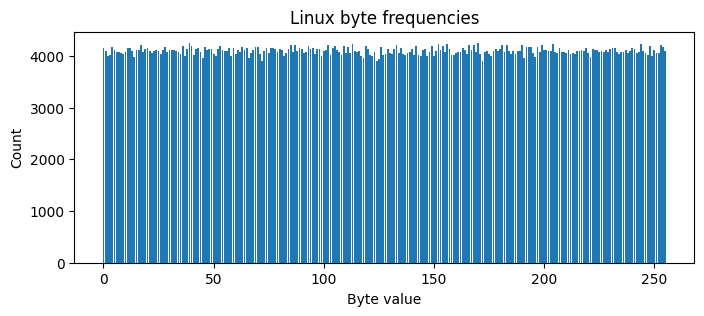

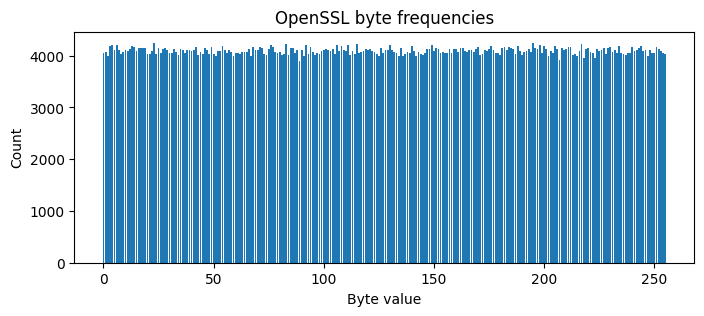

Missing: data/windows_cng.bin - upload the Windows file to data/


,Source,Bytes,Chi-square p-value,One-bit percentage,Bit-test p-value,Repeated 4-byte block types,Adjacent-byte correlation,Bit runs
0,Linux,1048576,0.121883,49.991131,0.607663,10,-0.000641,4194686
1,OpenSSL,1048576,0.772683,49.974394,0.138095,7,0.000520,4194812


In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, binomtest

# Generate Linux and OpenSSL files if not already present
os.makedirs("data", exist_ok=True)

if not os.path.exists("data/linux_urandom.bin"):
    with open("data/linux_urandom.bin", "wb") as f:
        f.write(open("/dev/urandom", "rb").read(1048576))

if not os.path.exists("data/openssl_rand.bin"):
    os.system("openssl rand -out data/openssl_rand.bin 1048576")

files = {
    "Linux": "data/linux_urandom.bin",
    "OpenSSL": "data/openssl_rand.bin",
    "Windows CNG": "data/windows_cng.bin"
}

results = []

for name, path in files.items():
    if not os.path.exists(path):
        print("Missing:", path, "- upload the Windows file to data/")
        continue

    data = np.fromfile(path, dtype=np.uint8)
    counts = np.bincount(data, minlength=256)
    chi, p = chisquare(counts)

    bits = np.unpackbits(data)
    ones = int(bits.sum())
    bit_p = binomtest(ones, len(bits), 0.5).pvalue

    correlation = np.corrcoef(data[:-1], data[1:])[0, 1]

    blocks = data[:len(data)//4*4].reshape(-1, 4)
    _, block_counts = np.unique(blocks, axis=0, return_counts=True)

    runs = 1 + np.count_nonzero(bits[1:] != bits[:-1])

    results.append({
        "Source": name,
        "Bytes": len(data),
        "Chi-square p-value": p,
        "One-bit percentage": 100 * ones / len(bits),
        "Bit-test p-value": bit_p,
        "Repeated 4-byte block types": int((block_counts > 1).sum()),
        "Adjacent-byte correlation": correlation,
        "Bit runs": int(runs)
    })

    plt.figure(figsize=(8, 3))
    plt.bar(range(256), counts)
    plt.title(name + " byte frequencies")
    plt.xlabel("Byte value")
    plt.ylabel("Count")
    plt.show()

results = pd.DataFrame(results)
display(results)
